# food-vision: results walkthrough

A visual tour of the project's real outputs: data, training, evaluation, error analysis and explainability.

* **Nothing is retrained here.** Every cell reads files produced by the scripts in `scripts/` (`data/splits/`, `runs/`, `reports/`), so the numbers are exactly those of the recorded runs.
* All logic lives in the `food_vision` package; this notebook only loads and displays results.
* To regenerate everything: `prepare_data.py` → `eda.py` → `zero_shot_clip.py` → `train.py --model cnn|vit` → `evaluate.py` → `explain.py`.

Task: classify 20 Food-101 dishes (incl. samosa and chicken curry) with three approaches on identical splits:
a fine-tuned **CNN** (EfficientNet-B0), a fine-tuned **ViT** (ViT-S/16), and **zero-shot CLIP** (no training).

In [1]:
import json
import os
from pathlib import Path

# Run from the repo root regardless of where Jupyter was started.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from food_vision.config import load_config
from food_vision.data import SPLITS, food101_dir, get_splits

pd.set_option("display.precision", 4)
cfg = load_config()
RUNS, REPORTS = cfg.train.runs_dir, cfg.data.reports_dir
NAMES = {"cnn": "EfficientNet-B0 (fine-tuned)", "vit": "ViT-S/16 (fine-tuned)", "clip": "CLIP ViT-B/32 (zero-shot)"}
print(f"{len(cfg.data.class_names)} classes, seed {cfg.seed}")

20 classes, seed 42


## 1. Data

Train and val are sampled without overlap from Food-101's official *train* list; test comes from the official *test* list, so no test image is ever used in training.

In [2]:
splits = get_splits(cfg)
counts = pd.DataFrame({s: pd.Series([x.class_name for x in splits[s]]).value_counts() for s in SPLITS})
counts.loc["TOTAL"] = counts.sum()
counts

,train,val,test
caesar_salad,300,75,100
chicken_curry,300,75,100
chocolate_cake,300,75,100
donuts,300,75,100
dumplings,300,75,100
filet_mignon,300,75,100
french_fries,300,75,100
fried_rice,300,75,100
frozen_yogurt,300,75,100
hamburger,300,75,100


In [3]:
eda = json.loads((REPORTS / "eda/summary.json").read_text())
{k: eda[k] for k in ["images_per_split", "corrupt_images", "non_rgb_images", "pct_longest_side_eq_512",
                     "duplicate_groups", "cross_split_duplicate_groups"]}

{'images_per_split': {'train': 6000, 'val': 1500, 'test': 2000},
 'corrupt_images': 0,
 'non_rgb_images': {},
 'pct_longest_side_eq_512': 100.0,
 'duplicate_groups': 0,
 'cross_split_duplicate_groups': 0}

The EDA's duplicate check (MD5 of the file bytes) originally found **two problems**, both now excluded in `configs/default.yaml`:

* the same photo filed as both `omelette` and `pancakes`. It shows both dishes, so a single label can't be right;
* one dumplings image present in both train and val (leakage).

The cross-label duplicate:

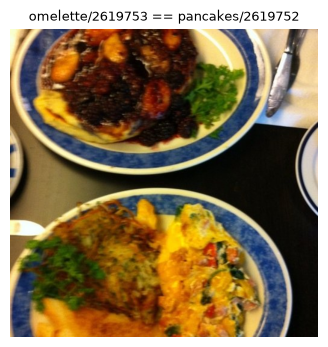

In [4]:
img_dir = food101_dir(cfg.data.root) / "images"
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(plt.imread(img_dir / "omelette/2619753.jpg")); ax.axis("off")
ax.set_title("omelette/2619753 == pancakes/2619752", fontsize=9);

Random training images per class:

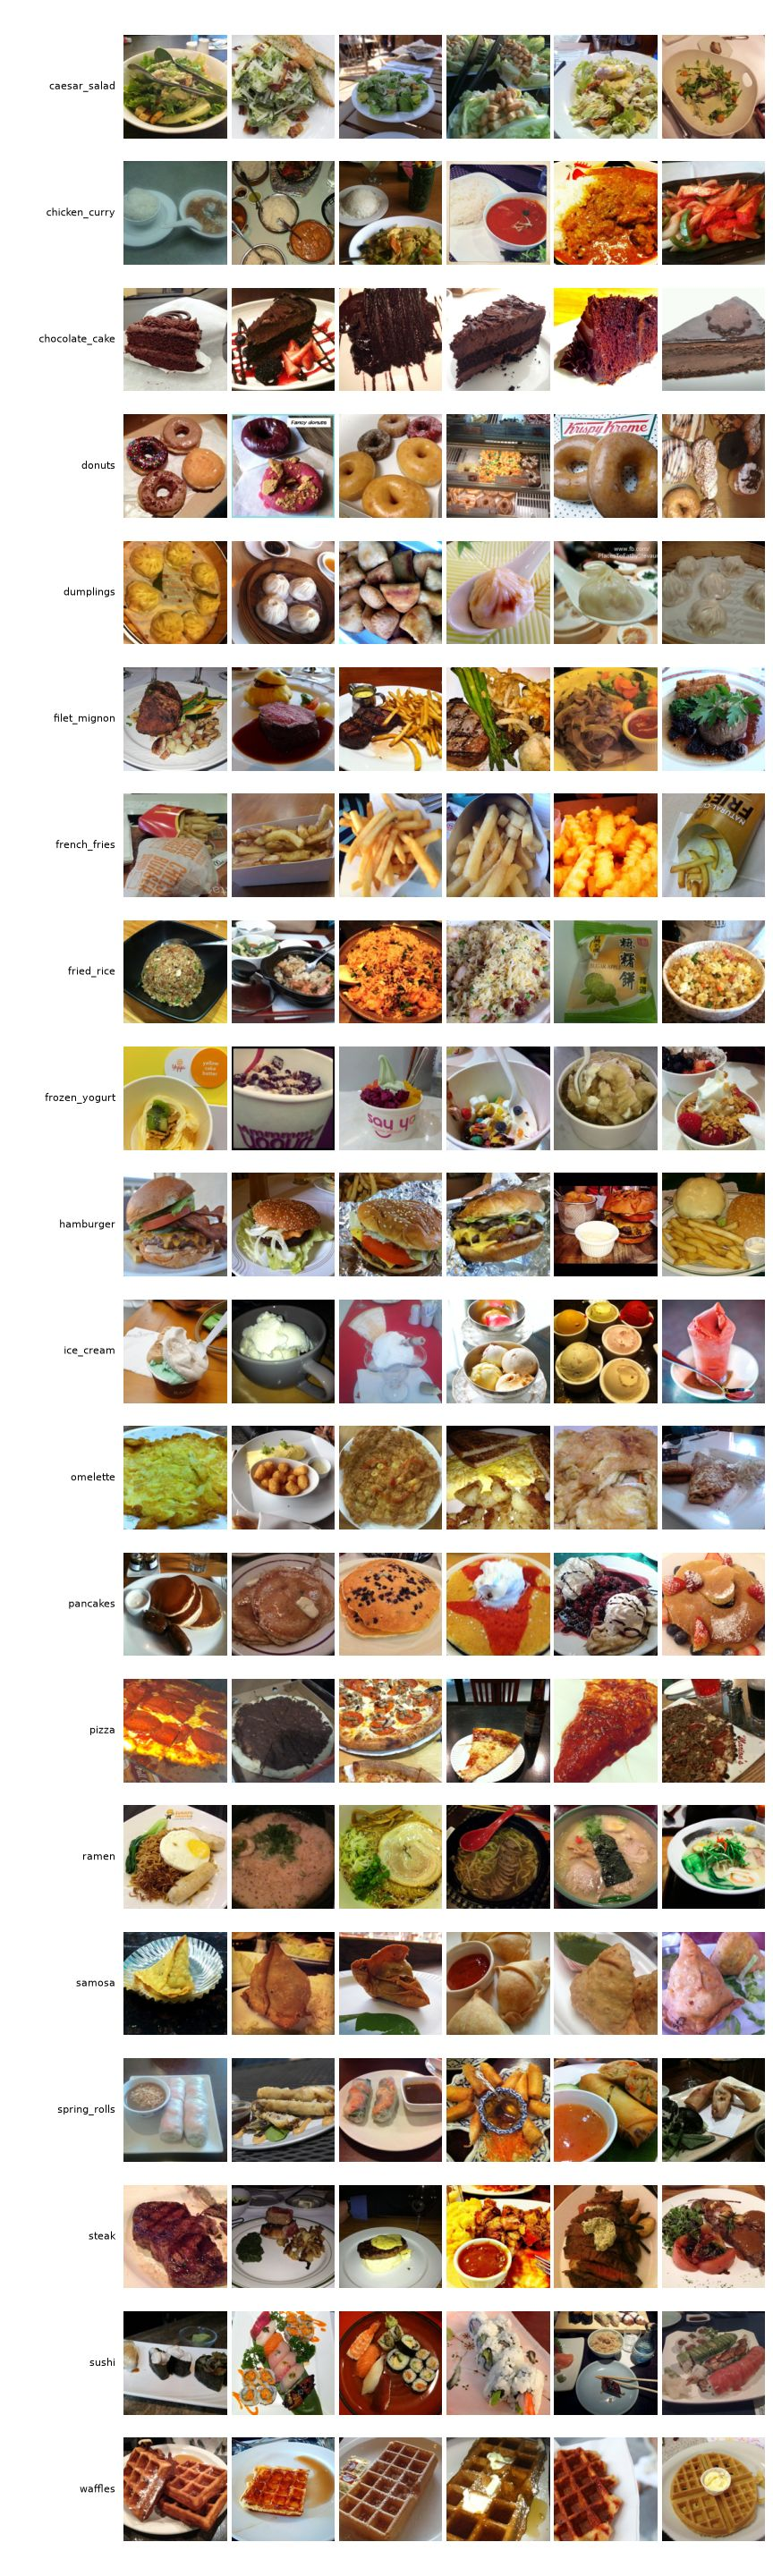

In [5]:
Image(str(REPORTS / "eda/sample_grid.jpg"), width=520)

## 2. Training curves

Both fine-tuned models use the same recipe: AdamW, warmup + cosine LR, label smoothing 0.1, fp16 mixed precision, early stopping on val top-1. The best-val checkpoint (★) is the one evaluated on test.

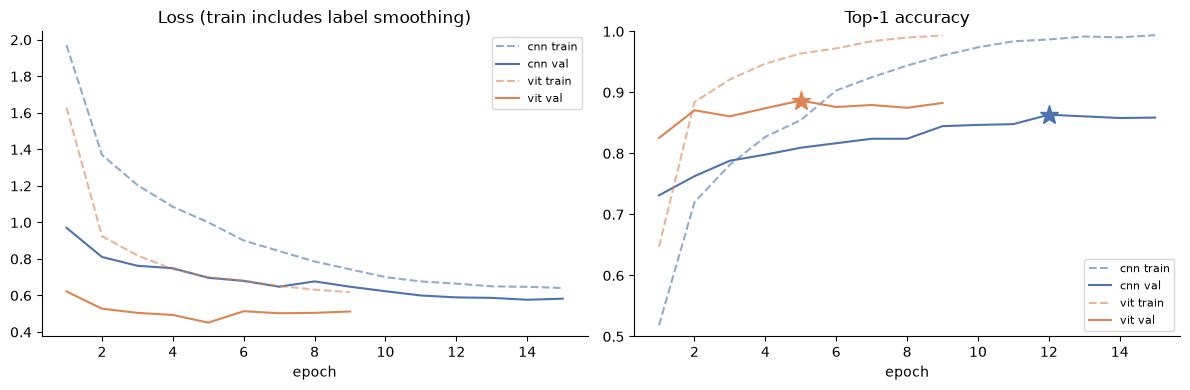

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for key, color in [("cnn", "#4C72B0"), ("vit", "#DD8452")]:
    m = pd.read_csv(RUNS / key / "metrics.csv")
    axes[0].plot(m.epoch, m.train_loss, "--", color=color, alpha=0.6, label=f"{key} train")
    axes[0].plot(m.epoch, m.val_loss, color=color, label=f"{key} val")
    axes[1].plot(m.epoch, m.train_top1, "--", color=color, alpha=0.6, label=f"{key} train")
    axes[1].plot(m.epoch, m.val_top1, color=color, label=f"{key} val")
    best = m.loc[m.val_top1.idxmax()]
    axes[1].plot(best.epoch, best.val_top1, "*", color=color, ms=14)
axes[0].set(title="Loss (train includes label smoothing)", xlabel="epoch")
axes[1].set(title="Top-1 accuracy", xlabel="epoch", ylim=(0.5, 1.0))
for ax in axes:
    ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

Train accuracy approaches 100% while val levels off well below it: with 300 images per class both models overfit, despite augmentation and label smoothing. The ViT reaches its best val score much earlier and stops early.

## 3. Model comparison

Test split: 2,000 images (100 per class). Latency is batch 1, fp32, forward pass only (mean / p95 over 50 runs after warm-up).

In [7]:
comp = pd.read_csv(REPORTS / "eval/comparison.csv", index_col="key")
view = comp[["model", "top1", "top5", "macro_f1", "errors", "params_inference",
             "mps_mean_ms", "mps_p95_ms", "cpu_mean_ms", "cpu_p95_ms"]].copy()
view["params_inference"] = (view["params_inference"] / 1e6).round(1).astype(str) + "M"
view.style.format({"top1": "{:.2%}", "top5": "{:.2%}", "macro_f1": "{:.4f}",
                   **{c: "{:.1f}" for c in view.columns if c.endswith("_ms")}}).hide(axis="index")

model,top1,top5,macro_f1,errors,params_inference,mps_mean_ms,mps_p95_ms,cpu_mean_ms,cpu_p95_ms
EfficientNet-B0 (fine-tuned),90.45%,98.30%,0.9047,190,4.0M,5.0,5.2,102.5,103.6
ViT-S/16 (fine-tuned),92.05%,99.25%,0.9200,159,21.7M,6.7,6.9,13.7,14.0
CLIP ViT-B/32 (zero-shot),92.70%,99.65%,0.9271,146,87.8M,9.0,9.2,21.0,21.6


**Are the differences real?** An exact McNemar test compares two models on the *same* images, using only the images where they disagree.

In [8]:
pd.read_csv(REPORTS / "eval/significance.csv")

,model_a,model_b,top1_a,top1_b,only_a_correct,only_b_correct,p_value
0,cnn,vit,0.9050,0.9205,67,98,0.0192
1,cnn,clip,0.9050,0.9270,78,122,0.0023
2,vit,clip,0.9205,0.9270,81,94,0.3644


* Zero-shot CLIP and the fine-tuned ViT are **statistically tied** (p ≈ 0.36). CLIP gets there without seeing a single training image.
* Both beat EfficientNet-B0 with p < 0.05.
* The EfficientNet **CPU** latency is distorted by this PyTorch build: it has no oneDNN, so depthwise convolutions use a slow fallback (see `reports/eval/summary.md`). The ONNX Runtime benchmark in Phase 4 measures the real CPU cost.

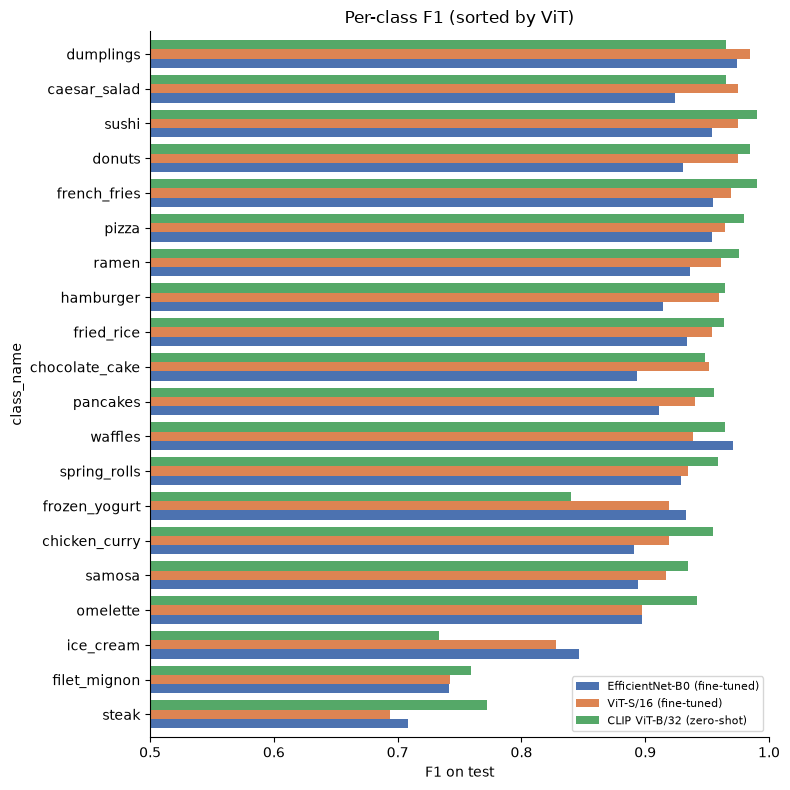

In [9]:
per_class = {k: pd.read_csv(REPORTS / f"eval/{k}_per_class.csv", index_col=0)
                .drop(["macro avg", "weighted avg"])["f1"] for k in NAMES}
f1 = pd.DataFrame(per_class).sort_values("vit")
ax = f1.plot.barh(figsize=(8, 8), width=0.8, color=["#4C72B0", "#DD8452", "#55A868"])
ax.set(xlabel="F1 on test", xlim=(0.5, 1.0), title="Per-class F1 (sorted by ViT)")
ax.legend([NAMES[k] for k in f1.columns], fontsize=8, loc="lower right")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

## 4. Error analysis

### Most-confused class pairs (errors in either direction)

In [10]:
pairs = []
for k in NAMES:
    p = pd.read_csv(REPORTS / f"eval/{k}_confused_pairs.csv").head(3)
    p.insert(0, "model", k)
    pairs.append(p)
pd.concat(pairs, ignore_index=True)

,model,class_a,class_b,a_as_b,b_as_a,total
0,cnn,filet_mignon,steak,18,25,43
1,cnn,frozen_yogurt,ice_cream,3,7,10
2,cnn,chocolate_cake,ice_cream,3,4,7
3,vit,filet_mignon,steak,18,24,42
4,vit,frozen_yogurt,ice_cream,2,12,14
5,vit,ice_cream,waffles,7,0,7
6,clip,filet_mignon,steak,27,15,42
7,clip,frozen_yogurt,ice_cream,7,25,32
8,clip,chocolate_cake,ice_cream,7,1,8


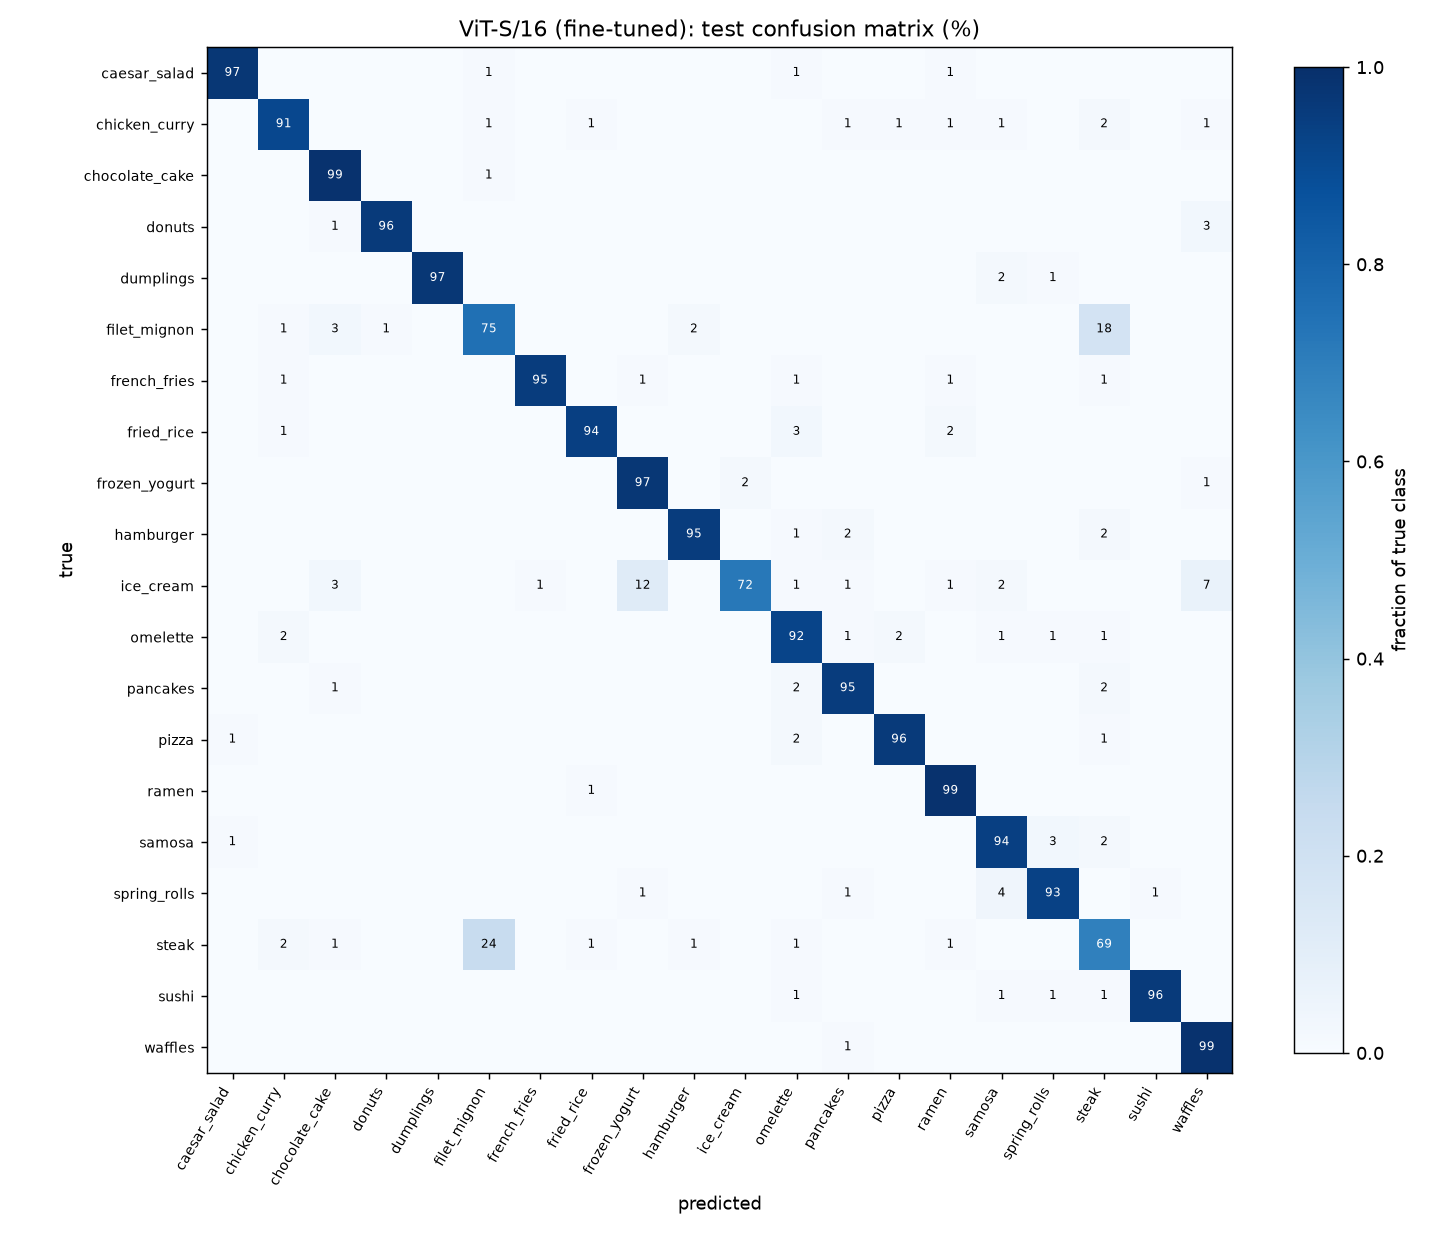

In [11]:
Image(str(REPORTS / "eval/vit_confusion.png"), width=720)

* **steak ↔ filet mignon** is the main weakness of *all three* models (about 42 errors each). It is a fine-grained distinction, since filet mignon *is* a steak cut.
* **ice cream → frozen yogurt** is hardest for zero-shot CLIP. Text prompts alone can't separate two desserts that look the same; labelled training data can.

### Most confidently wrong predictions (ViT)

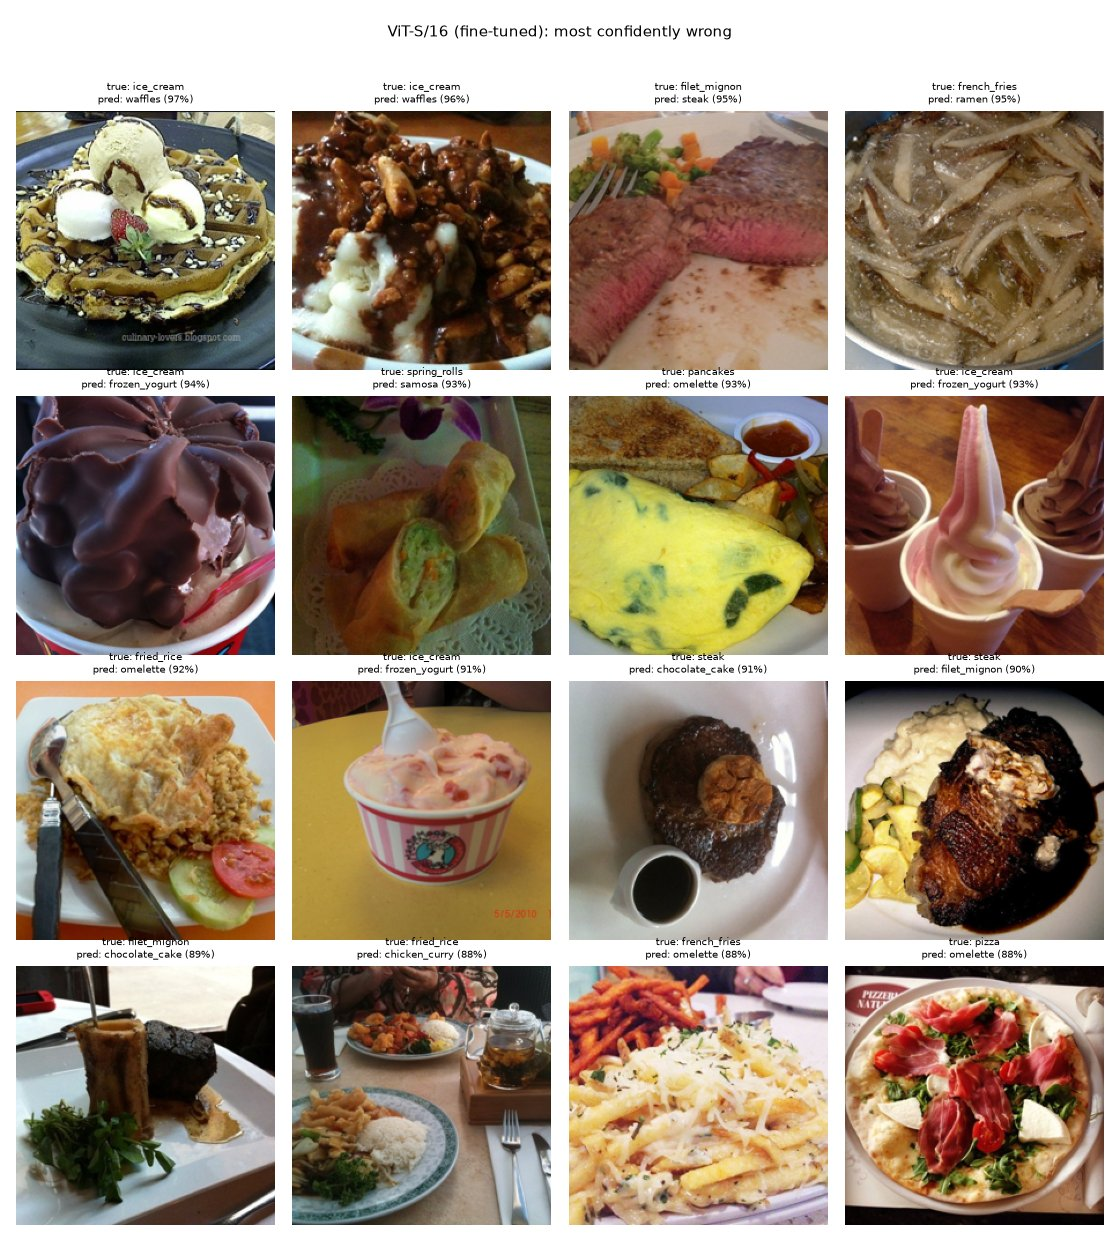

In [12]:
Image(str(REPORTS / "eval/vit_worst_errors.jpg"), width=720)

Many of the most confident errors are **multi-dish photos** (ice cream *on* waffles, a pastry beside a salad) or arguable labels. Here the image is ambiguous rather than the model wrong, which is the motivation for v2: multi-dish detection and segmentation.

### Images every model gets wrong

49 of 2000 test images are wrong for all three models


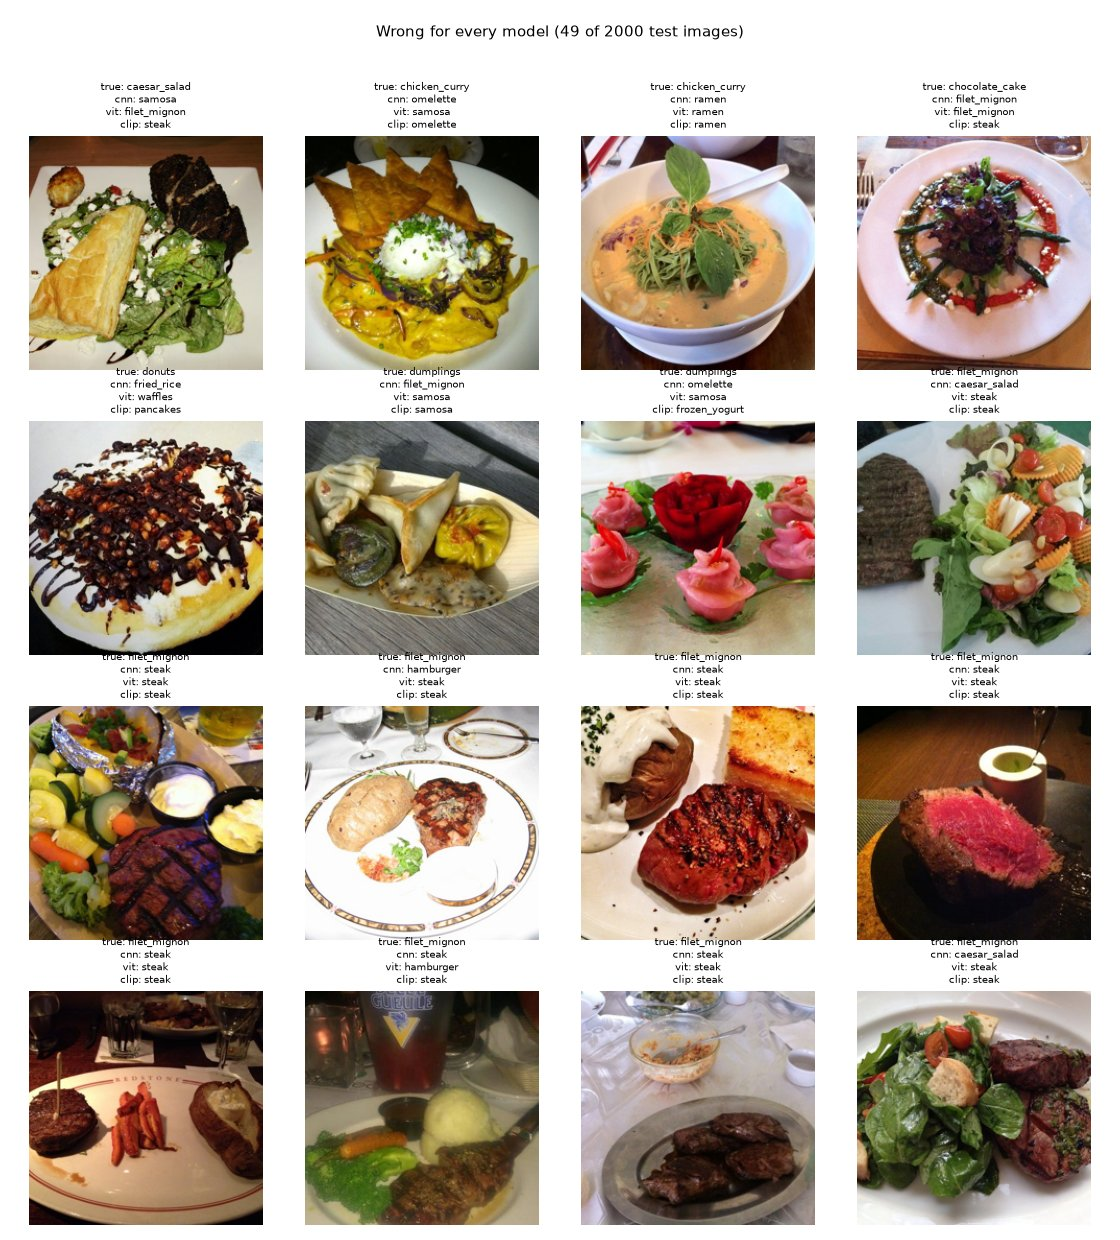

In [13]:
aw = pd.read_csv(REPORTS / "eval/all_wrong.csv")
print(f"{len(aw)} of {len(splits['test'])} test images are wrong for all three models")
Image(str(REPORTS / "eval/all_wrong.jpg"), width=720)

## 5. What do the models look at?

Same test images through both trained models: **Grad-CAM** for the CNN (gradient-weighted activations of the last conv block) and **attention rollout** for the ViT (attention weights multiplied through all 12 layers, read from the CLS token).

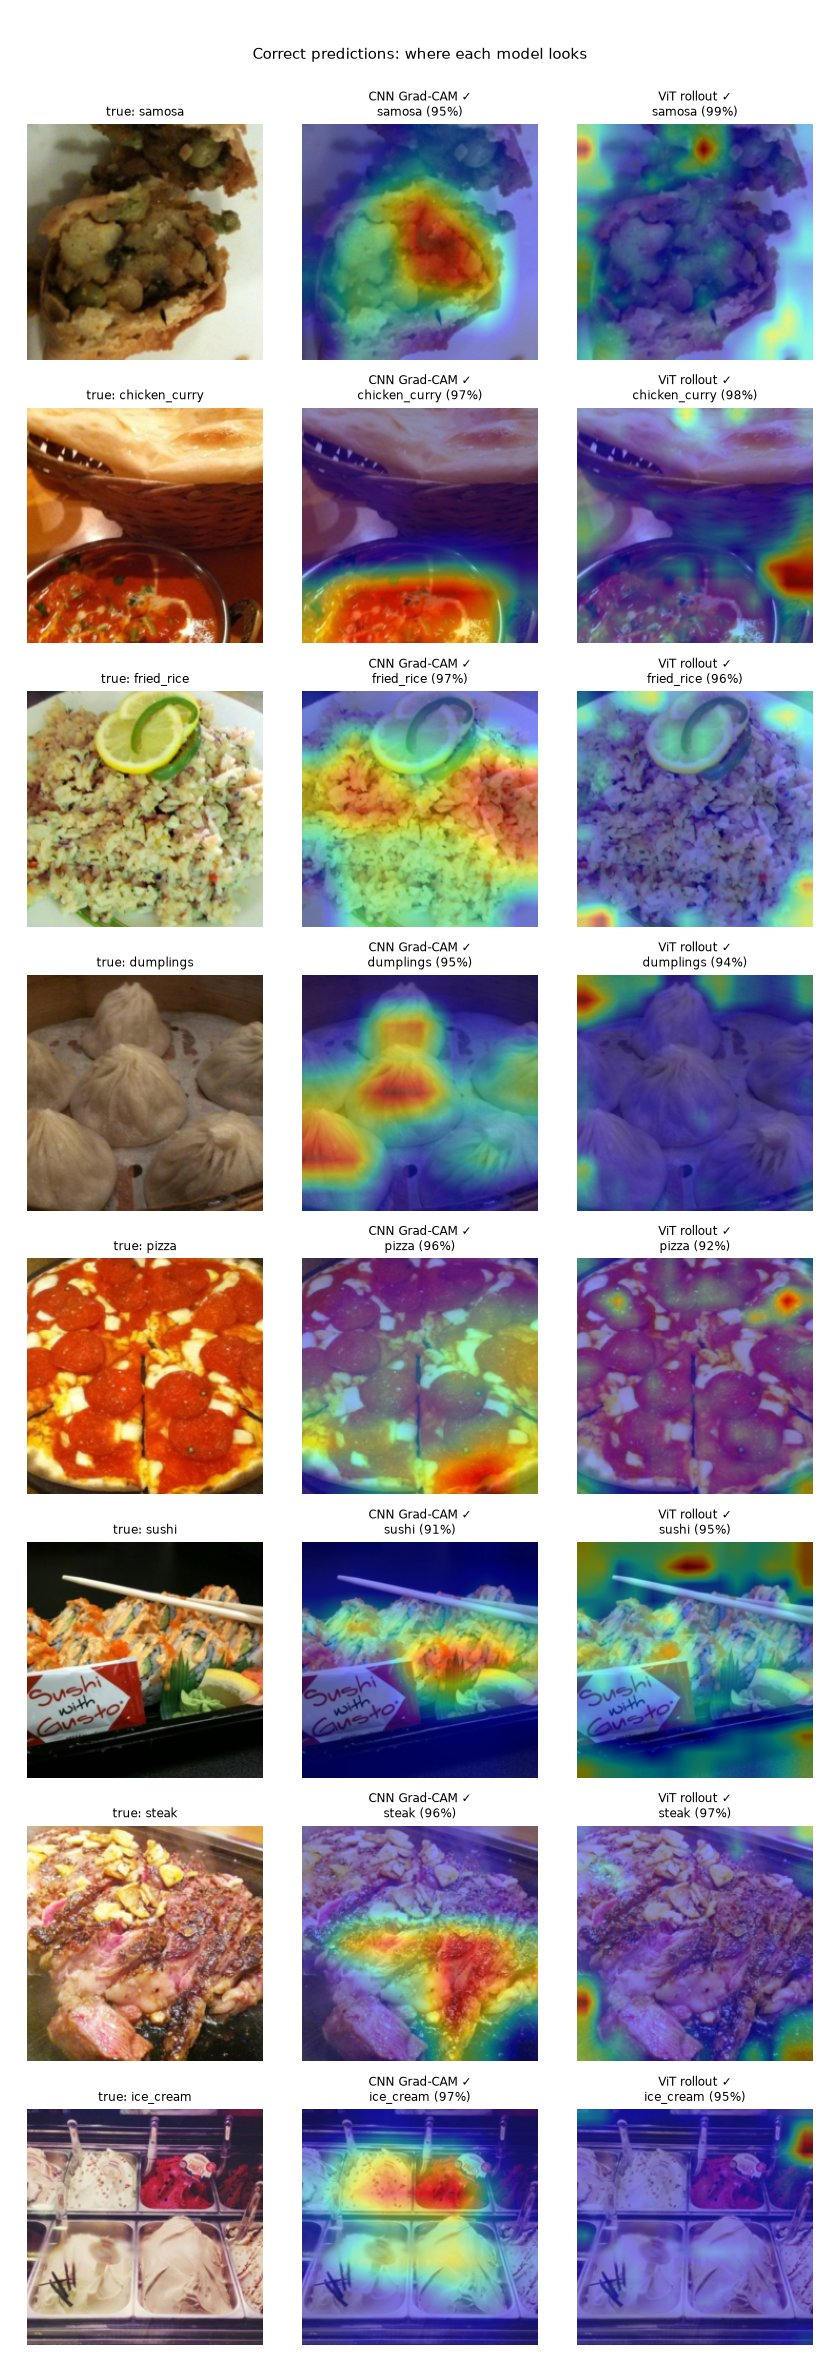

In [14]:
Image(str(REPORTS / "explain/correct.jpg"), width=620)

Grad-CAM consistently highlights the food itself. ViT rollout often lights up **background patches** (corners, borders, plain table areas). Is that a bug, or the model?

Darcet et al. (2023, *Vision Transformers Need Registers*) showed that ViTs repurpose a few low-information patches as global "scratch" storage. Those patches have unusually high norm and attract attention. `explain.py` tests this on 100 test images:

In [15]:
checks = pd.DataFrame(json.loads((REPORTS / "explain/artifact_check.json").read_text()))
checks[["layer", "num_images", "median_max_over_median_norm", "mean_topk_overlap",
        "chance_topk_overlap", "mean_corr_rollout_vs_norm"]]

,layer,num_images,median_max_over_median_norm,mean_topk_overlap,chance_topk_overlap,mean_corr_rollout_vs_norm
0,5,100,5.6470,0.628,0.0255,0.5781
1,8,100,11.3960,0.640,0.0255,0.5839
2,11,100,4.1049,0.630,0.0255,0.4872


Rollout's top-5 patches coincide with the top-5 highest-norm tokens far more often than chance, and those tokens' norms are many times the median. So the background hot spots are **artifact tokens, not evidence the model is looking at the table**. Plain attention rollout is misleading on standard ViTs; ViTs trained with register tokens are the documented fix.

### Explanations on errors

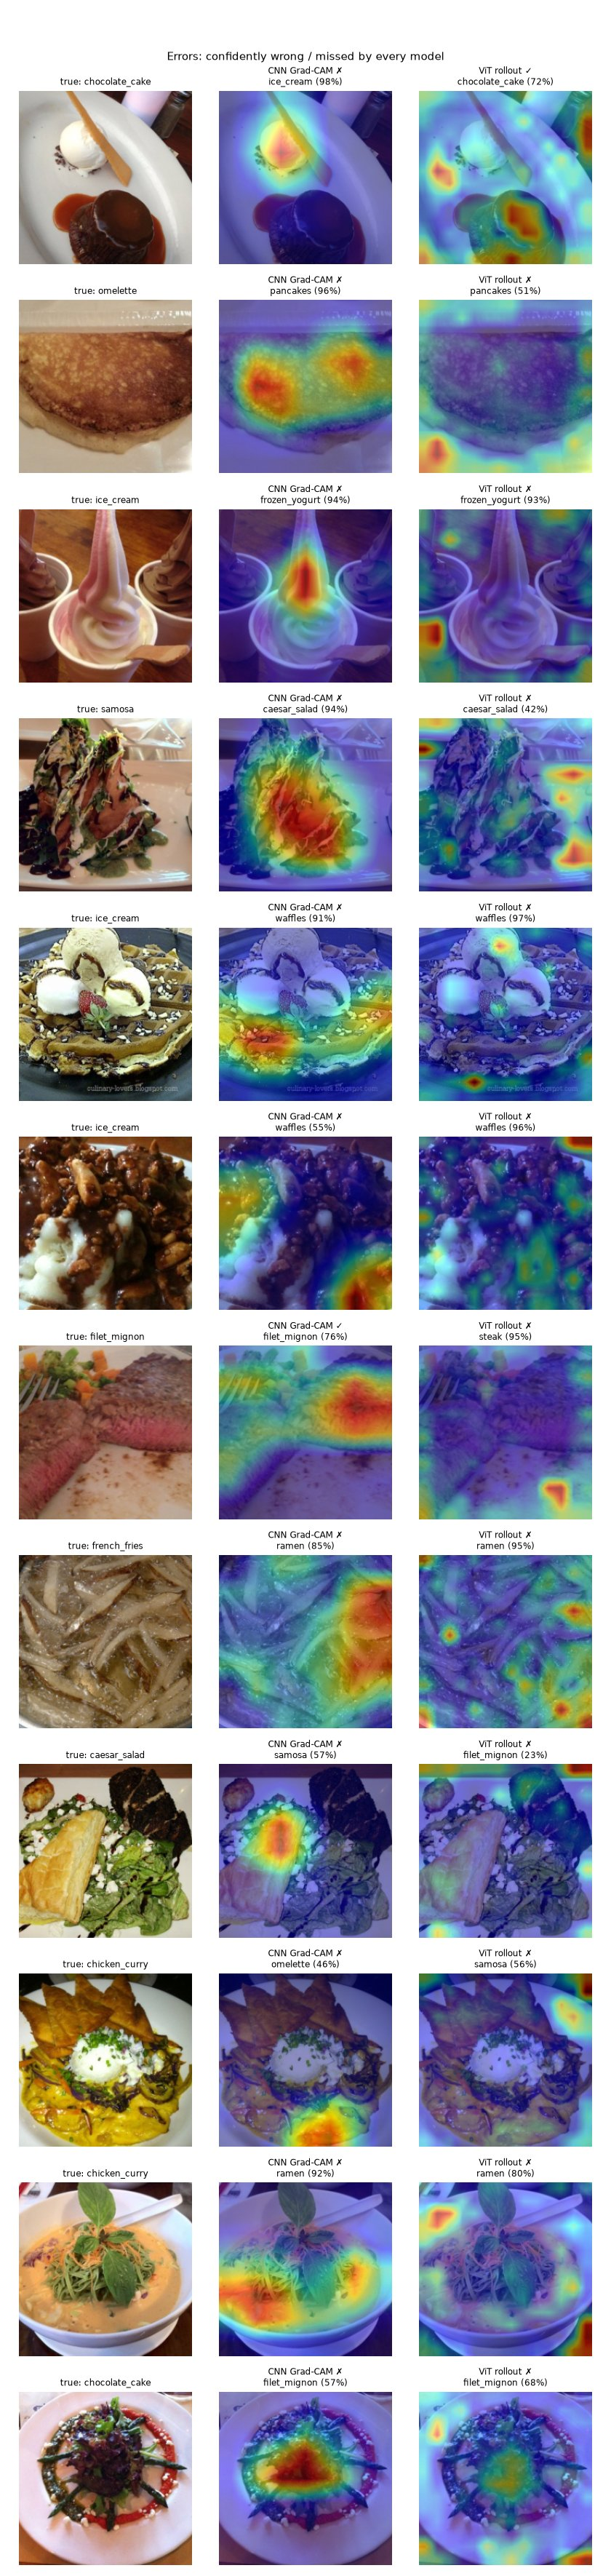

In [16]:
Image(str(REPORTS / "explain/errors.jpg"), width=620)

## 6. Try it on a test image

Load the best ViT checkpoint and predict the top-3 dishes for any image path.

[('caesar_salad', 0.8629463315010071),
 ('chicken_curry', 0.02088094688951969),
 ('pizza', 0.019092297181487083)]

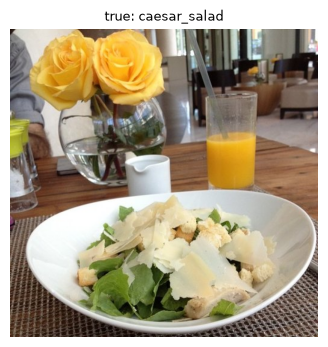

In [17]:
import warnings

warnings.filterwarnings("ignore", message="IProgress not found")  # tqdm notebook widget, unused here

import torch
from PIL import Image as PILImage

from food_vision.data import build_transforms
from food_vision.models import load_classifier

model, ckpt = load_classifier(RUNS / "vit/best.pt", "cpu")
pre = ckpt["preprocess"]
tf = build_transforms(pre.image_size, False, pre.mean, pre.std)

def top3(path):
    img = PILImage.open(path).convert("RGB")
    with torch.no_grad():
        probs = torch.softmax(model(tf(img).unsqueeze(0)), 1)[0]
    p, i = probs.topk(3)
    return img, [(ckpt["class_names"][j], float(q)) for q, j in zip(p, i)]

sample = splits["test"][0]  # change the index to try another image
img, preds = top3(img_dir / sample.rel_path)
plt.figure(figsize=(4, 4)); plt.imshow(img); plt.axis("off")
plt.title(f"true: {sample.class_name}", fontsize=9)
preds